# TV4 — Training và thực nghiệm LSTM
        **Đã hoàn thành 10 hạng mục TV4 tại workspace — training, thực nghiệm và bộ bàn giao local.**

        LSTM năm bước đã hoàn tất ba seed, tổng 300 epoch. Validation MSE tổng trung bình 0,007692942, std mẫu 0,000146946. [Đi tới kết quả năm bước](#tv4-item-9).

        Chín run đã hoàn tất với lookback 10/30/60 và seeds 42/123/456. Mỗi cấu hình dùng cùng 1.954 mẫu train và 250 mẫu validation. Chọn lookback 30 theo validation MSE trung bình thấp nhất.

        | Lookback | Validation MSE trung bình | Độ lệch chuẩn mẫu |
        |---|---:|---:|
        | 10 | 0,012245378 | 0,016262211 |
        | 30 | 0,003265939 | 0,001118952 |
        | 60 | 0,003563105 | 0,000768613 |

        Đi tới [mục 6 — smoke và CPU](#tv4-item-6), [mục 7 — audit và kế hoạch](#tv4-item-7), [mục 8 — chín run và biểu đồ](#tv4-item-8). Tại mục 8 có bảng từng seed và chín biểu đồ train/validation đã lưu output.

        Xem [mục 10 — kiểm chứng và tổng hợp đầu ra](#tv4-item-10). Xác nhận máy người nhận được ghi riêng khi có kết quả thực tế.
        Nguồn PR#10, commit16555929210314b1eb06da9dc84b827ececc1b9e; nhận9 file nguyên nội dung, đặt runner đúng backend/experiments/runner.
        Mục 2 dùng tensors tổng hợp. Mục 3 kiểm tra toàn bộ batch train/validation AAPL bằng hai LSTM TV3.
        Mục tiêu bài: TV4 huấn luyện hai LSTM TV3 trên dữ liệu TV2, chọn checkpoint bằng validation để TV6 đánh giá sau.

In [1]:
from pathlib import Path
import sys
from datetime import datetime, timezone

cwd = Path.cwd().resolve()
ROOT = next((folder for folder in (cwd, *cwd.parents)
             if (folder / 'rule.md').is_file() and (folder / 'backend/training/trainer.py').is_file()), None)
if ROOT is None:
    raise RuntimeError(f'Hãy mở notebook trong thư mục project. Thư mục kernel hiện tại là {cwd}')
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

import json, os, subprocess, hashlib
import xml.etree.ElementTree as ET
import pandas as pd
from IPython.display import display, Markdown
print('Executed UTC:',datetime.now(timezone.utc).isoformat())
print('Python:',sys.executable)
print('TV4 mục 1–4 | Kiểm thử, dữ liệu AAPL và quản lý run')

Executed UTC: 2026-11-25T13:04:35.468247+00:00
Python: D:\learn_DeepLearning\Project_course-work\.venv\tv4_clean\Scripts\python.exe
TV4 mục 1–4 | Kiểm thử, dữ liệu AAPL và quản lý run


## 1. Tiếp nhận source và sửa import
        Đầu vào: source PR#10 đã audit, không nhận toàn nhánh bằng cách ghi đè workspace.
        Đầu ra: trainer, runner, manager, hai YAML và ba file tests đúng module.
        Receipt bên dưới ghi hash của các file lúc tiếp nhận. Mục 3 cập nhật hai YAML để sử dụng đúng snapshot và scaler của TV2.

In [2]:
from backend.training import trainer
from backend.experiments.runner import experiment_runner
from backend.experiments.management import experiment_manager
modules=[trainer,experiment_runner,experiment_manager]
rows=[]
for module in modules:
    p=Path(module.__file__).resolve()
    assert p.is_relative_to(ROOT/'backend')
    rows.append({'module':module.__name__,'file':p.relative_to(ROOT).as_posix()})
display(pd.DataFrame(rows))
intake_path=ROOT/'logs/audit/tv4_item1_20261125/intake.json'
if intake_path.is_file():
    intake=json.loads(intake_path.read_text(encoding='utf-8'))
    display(pd.DataFrame(intake['files']))
    print('PR:',intake['pr'],'| commit:',intake['head'],'| source content unchanged at intake:',intake['source_content_unchanged'])
else:
    print('Không có receipt tiếp nhận trên máy này; source/lock được kiểm bằng runner bên dưới.')

,module,file
0,backend.training.trainer,backend/training/trainer.py
1,backend.experiments.runner.experiment_runner,backend/experiments/runner/experiment_runner.py
2,backend.experiments.management.experiment_manager,backend/experiments/management/experiment_mana...


,source_path,workspace_path,sha256
0,backend/training/trainer.py,backend/training/trainer.py,85f22f46cec1db4bccc145814fa712ca242e3c4927aac6...
1,backend/training/__init__.py,backend/training/__init__.py,32d133d97cb2c881f762681cecda0bee94948ef4fb0a1a...
2,backend/experiments/management/experiment_mana...,backend/experiments/management/experiment_mana...,cedec95f1f8ef3f7714eeff4bdaf51fa9d216028fb8fe8...
3,backend/experiments/management/experiment_runn...,backend/experiments/runner/experiment_runner.py,e090b58cab737b98b56f78154a662550bf78df90db8298...
4,experiments/configs/lstm_one_step_baseline.yaml,experiments/configs/lstm_one_step_baseline.yaml,76a98977fd7fa2796269bec599135ce8b88f3e732acd67...
5,experiments/configs/lstm_multi_step_baseline.yaml,experiments/configs/lstm_multi_step_baseline.yaml,d085d43405309ce4b6099666f6dc3f77b8df64fe8db3ee...
6,tests/training/test_experiment_manager.py,tests/training/test_experiment_manager.py,389eb291f9416f89069756251f72527033920c8190edb2...
7,tests/training/test_experiment_runner.py,tests/training/test_experiment_runner.py,185f89ddb2eaab7c4551b940a4a670e7eb43aac40a2477...
8,tests/training/test_training_loop.py,tests/training/test_training_loop.py,6e88508ead68f0577762341965ba5f6d2b6a38d4e4ddf2...


PR: 10 | commit: 16555929210314b1eb06da9dc84b827ececc1b9e | source content unchanged at intake: True


### Kiểm thử baseline từ workspace
        Chạy tests trực tiếp, không alias import và không lấy code từ checkout audit.
        Các tests dùng tensor tổng hợp; checkpoint được mock. Một phép thử học hồi quy tuyến tính là bằng chứng loop tổng hợp, không phải training AAPL.
        Môi trường TV4 riêng không kế thừa system/user packages, khớp lock có PyYAML.

In [3]:
env=dict(os.environ,OMP_NUM_THREADS='1',MKL_NUM_THREADS='1',PYTHONIOENCODING='utf-8')
env.pop('PYTHONPATH',None)
run=subprocess.run([sys.executable,'-X','utf8',str(ROOT/'scripts/run_tv4_checks.py'),'--require-clean'],cwd=ROOT,env=env,capture_output=True,text=True,encoding='utf-8')
print(run.stdout)
if run.returncode: raise RuntimeError(run.stderr or run.stdout)
receipt=json.loads(run.stdout)
summary_path=Path(receipt['evidence'])
summary=json.loads(summary_path.read_text(encoding='utf-8'))
assert summary['passed'] and summary['workspace_imports'] and summary['source_unchanged_during_tests']
assert summary['counts']['tests']>0 and all(summary['counts'][k]==0 for k in ['failures','errors','skipped'])
cases=[]
for case in ET.parse(summary_path.parent/'junit.xml').getroot().iter('testcase'):
    cases.append({'suite':case.get('classname'),'test':case.get('name'),'seconds':case.get('time'),'result':'FAIL' if case.find('failure') is not None or case.find('error') is not None else 'SKIP' if case.find('skipped') is not None else 'PASS'})
with pd.option_context('display.max_rows',None,'display.max_colwidth',120): display(pd.DataFrame(cases))
print('Evidence:',summary_path)

{
  "passed": true,
  "counts": {
    "tests": 67,
    "failures": 0,
    "errors": 0,
    "skipped": 0
  },
  "clean_environment": true,
  "workspace_imports": true,
  "evidence": "D:\\learn_DeepLearning\\Project_course-work\\logs\\audit\\tv4_tests_20261125T130450008263Z\\summary.json"
}



,suite,test,seconds,result
0,tests.training.test_aapl_factories,test_factory_rejects_incompatible_configuration[data-forecast_length-5],0.004,PASS
1,tests.training.test_aapl_factories,test_factory_rejects_incompatible_configuration[data-lookback-29],0.004,PASS
2,tests.training.test_aapl_factories,test_factory_rejects_incompatible_configuration[data-ticker-MSFT],0.005,PASS
3,tests.training.test_aapl_factories,test_factory_rejects_incompatible_configuration[model-num_layers-2],0.005,PASS
4,tests.training.test_aapl_factories,test_factory_rejects_incompatible_configuration[model-output_size-5],0.005,PASS
5,tests.training.test_aapl_factories,test_factory_rejects_incompatible_configuration[training-batch_size-0],0.004,PASS
6,tests.training.test_aapl_factories,test_factory_rejects_substituted_scaler_manifest,0.019,PASS
7,tests.training.test_experiment_manager,test_random_seed_reproducible,0.027,PASS
8,tests.training.test_experiment_manager,test_generate_run_id,0.001,PASS
9,tests.training.test_experiment_manager,test_create_run_directory,0.007,PASS


Evidence: D:\learn_DeepLearning\Project_course-work\logs\audit\tv4_tests_20261125T130450008263Z\summary.json


In [4]:
assert summary['require_clean'] and summary['clean_environment']
assert summary['user_site_enabled'] is False and summary['cpu_torch_build']
assert not summary['lock_mismatches'] and summary['pip_check_exit_code']==0
display(pd.DataFrame([{'module':name,'source':path} for name,path in summary['module_origins'].items()]))
display(pd.DataFrame([{'prefix':summary['prefix'],'CPU_torch':summary['cpu_torch_build'],'lock_SHA256':summary['lock_sha256'],'protected_changes':summary['protected_changes_since_intake']}]))
print((summary_path.parent/'pip-check.log').read_text(encoding='utf-8'))
print((summary_path.parent/'requirements-freeze.txt').read_text(encoding='utf-8'))

,module,source
0,torch,D:\learn_DeepLearning\Project_course-work\.ven...
1,numpy,D:\learn_DeepLearning\Project_course-work\.ven...
2,pandas,D:\learn_DeepLearning\Project_course-work\.ven...
3,yaml,D:\learn_DeepLearning\Project_course-work\.ven...
4,pytest,D:\learn_DeepLearning\Project_course-work\.ven...
5,nbformat,D:\learn_DeepLearning\Project_course-work\.ven...
6,nbclient,D:\learn_DeepLearning\Project_course-work\.ven...
7,ipykernel,D:\learn_DeepLearning\Project_course-work\.ven...


,prefix,CPU_torch,lock_SHA256,protected_changes
0,D:\learn_DeepLearning\Project_course-work\.ven...,True,38a01c8ed3bbf78cadd1bef912f40457635a663e5d2a29...,"[backend/data/preparation/contracts.py, backen..."


No broken requirements found.

asttokens==3.0.2
attrs==26.1.0
cloudpickle==3.1.2
colorama==0.4.6
comm==0.2.3
contourpy==1.3.3
cycler==0.12.1
debugpy==1.8.22
exchange_calendars==4.13.3
executing==2.3.0
fastjsonschema==2.22.3
filelock==4.2.4
fonttools==4.62.1
fsspec==2026.9.0
iniconfig==2.3.1
ipykernel==7.4.0
ipython==9.17.1
ipython_pygments_lexers==1.1.1
jedi==0.20.1
Jinja2==3.1.6
joblib==1.6.0
jsonschema==4.26.0
jsonschema-specifications==2025.9.1
jupyter_client==8.10.0
jupyter_core==5.9.1
kiwisolver==1.5.0
korean_lunar_calendar==0.4.0
MarkupSafe==3.0.3
matplotlib==3.10.9
matplotlib-inline==0.2.2
mpmath==1.3.0
narwhals==2.28.0
nbclient==0.11.0
nbformat==5.11.1
nest-asyncio2==1.7.4
networkx==3.7
numpy==2.4.4
packaging==26.2
pandas==3.0.6
parso==0.8.7
pillow==11.3.0
pip==25.2
platformdirs==4.13.5
pluggy==1.7.0
prompt_toolkit==3.0.53
psutil==7.2.2
pure_eval==0.2.4
Pygments==2.21.0
pyluach==2.3.0
pyparsing==3.3.2
pytest==9.2.0
python-dateutil==2.9.0.post0
PyYAML==6.0.3
pyzmq==27.2.0
refere

## 2. Contract CPU float64 với LSTM TV3
        Giữ dtype input/target, không tự cast hoặc di chuyển model. Hai LSTM yêu cầu CPU float64, một feature, horizon1/5; input(B,30,1), target(B,H).
        Loop chung vẫn hỗ trợ dtype của model tổng hợp khác; đây không phải quyết định dtype CNN. Lookback10/60 chỉ kiểm shape, chưa chạy thí nghiệm.
        Probe sau gọi loop thật với3 mẫu tổng hợp, batch2 nên batch cuối là1; kiểm Adam update, validation không thay weights/gradient, input không đổi và từ chốifloat32.
        Loss ở đây là diagnostic tổng hợp, không phải MAE/RMSE AAPL hoặc bằng chứng model dự báo tốt.

In [5]:
probe=subprocess.run([sys.executable,'-X','utf8',str(ROOT/'scripts/check_tv4_float64.py')],cwd=ROOT,env=env,capture_output=True,text=True,encoding='utf-8')
print(probe.stdout)
if probe.returncode: raise RuntimeError(probe.stderr or probe.stdout)
contract_path=Path(json.loads(probe.stdout)['evidence'])
contract=json.loads(contract_path.read_text(encoding='utf-8'))
assert contract['passed'] and contract['default_dtype_unchanged']
display(pd.DataFrame(contract['checks']))
print('Contract evidence:',contract_path)
display(Markdown('**CPU float64 đạt cho hai LSTM trong loop tổng hợp. Không có checkpoint AAPL.**'))

{
  "passed": true,
  "evidence": "D:\\learn_DeepLearning\\Project_course-work\\logs\\audit\\tv4_float64_20261125T130528551158Z\\summary.json"
}



,model,X_shape,y_shape,X_dtype,target_dtype,parameter_dtype,device,train_loss_synthetic,validation_loss_synthetic,train_batch_sizes,validation_batch_sizes,weights_updated,validation_weights_gradients_unchanged,float32_rejected,finite_parameters_gradients
0,LSTMOneStep,"[3, 30, 1]","[3, 1]",torch.float64,torch.float64,torch.float64,cpu,0.001060,0.000447,"[2, 1]","[2, 1]",True,True,True,True
1,LSTMMultiStep,"[3, 30, 1]","[3, 5]",torch.float64,torch.float64,torch.float64,cpu,0.006584,0.005093,"[2, 1]","[2, 1]",True,True,True,True


Contract evidence: D:\learn_DeepLearning\Project_course-work\logs\audit\tv4_float64_20261125T130528551158Z\summary.json


**CPU float64 đạt cho hai LSTM trong loop tổng hợp. Không có checkpoint AAPL.**

## 3. Dữ liệu AAPL từ TV2 đến hai LSTM
        Hai cấu hình YAML chỉ định phiên bản snapshot, scaler và bộ cửa sổ đã chuẩn bị. TV4 đối chiếu hash, thống kê scaler trên train và ngày target với lịch phiên. Mỗi batch giữ ID cùng X và y. Bảng bên dưới lấy từ một lượt forward qua toàn bộ train và validation theo thứ tự thời gian. Dòng năm bước có ít mẫu hơn vì cả năm target phải thuộc cùng tập.

In [6]:
data_check=subprocess.run([sys.executable, str(ROOT/'scripts/check_tv4_aapl_data.py')],cwd=ROOT,env=env,capture_output=True,text=True,encoding='utf-8')
if data_check.returncode: raise RuntimeError(data_check.stderr or data_check.stdout)
data_path=Path(json.loads(data_check.stdout)['evidence'])
data_report=json.loads(data_path.read_text(encoding='utf-8'))
assert data_report['passed']
display(pd.DataFrame([row for result in data_report['results'] for row in result['checks']])[['horizon','split','samples','batches','final_batch','first_origin','first_target','last_target']])
display(data_report['results'][0]['provenance'])
print('Evidence:', data_path)

,horizon,split,samples,batches,final_batch,first_origin,first_target,last_target
0,1,train,1984,62,32,2015-02-13,2015-02-17,2022-12-30
1,1,val,250,8,26,2022-12-30,2023-01-03,2023-12-29
2,5,train,1980,62,28,2015-02-13,2015-02-17,2022-12-30
3,5,val,246,8,22,2022-12-30,2023-01-03,2023-12-29


{'dataset_version': 'aapl_2015_2025_acq_20261119T141302002415Z',
 'source_hashes': {'raw': 'cbcadbc002d05bc27a573114b9bb73b930733585b7823d147ca3477354479351',
  'metadata': '71213959ec9c111a1826db9058dc41f61772af9a0324a4e32ff61eb3bf0edc24',
  'validated': 'ee56f9c782ac9e938985c680a9015d1ae198982e7d1cddc49ee5d67630c7b16d',
  'validation_report': '4c28421c1488cfa3451fbd9661eed9fc4874a9295389e9221ed100fd10c2aa85',
  'quality_audit': 'f78e41b5006679a32aa97e454d3597ec0847979bcc727ce858a60d73d203e52d'},
 'scaler_id': 'aapl_scaler_20261120T124720810874Z',
 'prepared_id': 'tv2_prepared_20261122T145943242978Z',
 'scaler_path': 'artifacts/scalers/aapl_scaler_20261120T124720810874Z',
 'scaler_manifest_sha256': '695905a39615e336f83de1ab781f4f893e599e59a5e2685d1e77e4881174b4f5',
 'prepared_manifest_sha256': '6f4dfb5632ce108a8585ec47a602efe942a3fd940ebf4926a18c90587b67450c'}

Evidence: D:\learn_DeepLearning\Project_course-work\logs\audit\tv4_item3_20261125T130608487365Z\summary.json


### 3.1. Quan sát LSTM học trên dữ liệu AAPL

Với kernel TV4 vừa mở, có thể bắt đầu ngay từ cell bên dưới rồi chạy lần lượt các cell còn lại của mục 3.1.

Phần minh họa dùng LSTM một bước trên CPU float64 và scaler đã fit trên train. Mỗi mẫu gồm 30 giá đóng cửa điều chỉnh để dự báo phiên kế tiếp.

**Một batch.** Xem dự báo cho cùng một cửa sổ trước và sau khi Adam cập nhật trọng số từ 32 mẫu. Gradient cho biết loss thay đổi theo trọng số như thế nào.

**Năm epoch.** Mô hình bắt đầu lại từ cùng seed 42. Mỗi epoch đi qua toàn bộ tập train một lần, rồi đo loss trên toàn bộ validation năm 2023 với trọng số vừa học. Hai đường trên biểu đồ đều là MSE trên giá đã chuẩn hóa. Đây là lần chạy minh họa để đọc quá trình học.

In [7]:
from pathlib import Path
import sys
from datetime import datetime, timezone

cwd = Path.cwd().resolve()
ROOT = next((folder for folder in (cwd, *cwd.parents)
             if (folder / 'rule.md').is_file() and (folder / 'backend/training/trainer.py').is_file()), None)
if ROOT is None:
    raise RuntimeError(f'Hãy mở notebook trong thư mục project. Thư mục kernel hiện tại là {cwd}')
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

import torch
import pandas as pd
from IPython.display import display
from backend.experiments.runner.experiment_runner import load_experiment_config
from backend.experiments.runner.aapl_factories import make_aapl_loaders, make_aapl_model
from backend.training.trainer import _run_epoch

demo_config = load_experiment_config(ROOT / 'experiments/configs/lstm_one_step_baseline.yaml')
demo_seed = demo_config['seeds'][0]
demo_train, demo_val = make_aapl_loaders(demo_config, demo_seed, project_root=ROOT)
demo_lr = demo_config['training']['learning_rate']
criterion = torch.nn.MSELoss()
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import LogNorm
from backend.artifacts.scaler import load_scaler
from backend.data.transforms.scaling import inverse_scale

provenance = demo_train.dataset.provenance
demo_scaler, _ = load_scaler(ROOT / provenance['scaler_path'],
                             expected_dataset_version=provenance['dataset_version'],
                             expected_source_hashes=provenance['source_hashes'])
demo_stamp = datetime.now(timezone.utc).strftime('%Y%m%dT%H%M%S%fZ')
demo_dir = ROOT / 'logs' / 'audit' / f'tv4_training_demo_{demo_stamp}'
demo_dir.mkdir(parents=True)

def show_figure(fig, name):
    fig.savefig(demo_dir / name, dpi=155, bbox_inches='tight', facecolor='white')
    plt.show()
    plt.close(fig)

def new_demo_model():
    with torch.random.fork_rng(devices=[]):
        torch.manual_seed(demo_seed)
        return make_aapl_model(demo_config)

print(f"LSTM một bước | train {len(demo_train.dataset)} mẫu | validation {len(demo_val.dataset)} mẫu")
print(f"Adam | learning rate {demo_lr} | batch {demo_train.batch_size} | seed {demo_seed}")

LSTM một bước | train 1984 mẫu | validation 250 mẫu
Adam | learning rate 0.001 | batch 32 | seed 42


In [8]:
batch_model = new_demo_model()
first_batch = next(iter(demo_train))
x, y, ids = first_batch
weights_before = batch_model.fc.weight.detach().clone()
with torch.no_grad():
    prediction_before = batch_model(x)[0, 0].item()
optimizer = torch.optim.Adam(batch_model.parameters(), lr=demo_lr)
batch_mse = _run_epoch(batch_model, [first_batch], criterion, optimizer)
with torch.no_grad():
    prediction_after = batch_model(x)[0, 0].item()
    step_size = (batch_model.fc.weight - weights_before).norm().item()
assert step_size > 0
print('Mẫu đầu tiên trong batch:', ids[0])
display(pd.DataFrame([{'Target (chuẩn hóa)': y[0, 0].item(),
                       'Dự báo trước Adam': prediction_before, 'Dự báo sau Adam': prediction_after,
                       'MSE cả batch trước Adam': batch_mse, 'Chuẩn L2 gradient lớp cuối': batch_model.fc.weight.grad.norm().item(),
                       'Chuẩn L2 thay đổi trọng số lớp cuối': step_size}]))

Mẫu đầu tiên trong batch: aapl_2015_2025_acq_20261119T141302002415Z:lb30:f1:2015-02-13


,Target (chuẩn hóa),Dự báo trước Adam,Dự báo sau Adam,MSE cả batch trước Adam,Chuẩn L2 gradient lớp cuối,Chuẩn L2 thay đổi trọng số lớp cuối
0,-0.858999,-0.148748,-0.161221,0.510572,0.655636,0.005657


#### Một cửa sổ và một lần cập nhật Adam

Bên trái, đường xanh kết thúc ở phiên gần nhất mô hình đã quan sát. Ba điểm ở phiên kế tiếp là giá thực tế và hai lần dự báo cho cùng một cửa sổ, trước và sau khi học batch đầu tiên. Giá được đổi về USD bằng scaler TV2. Bên phải, mỗi cột là thay đổi của một trọng số nối tầng LSTM với đầu ra. Cột âm cho biết trọng số giảm sau lần cập nhật này.

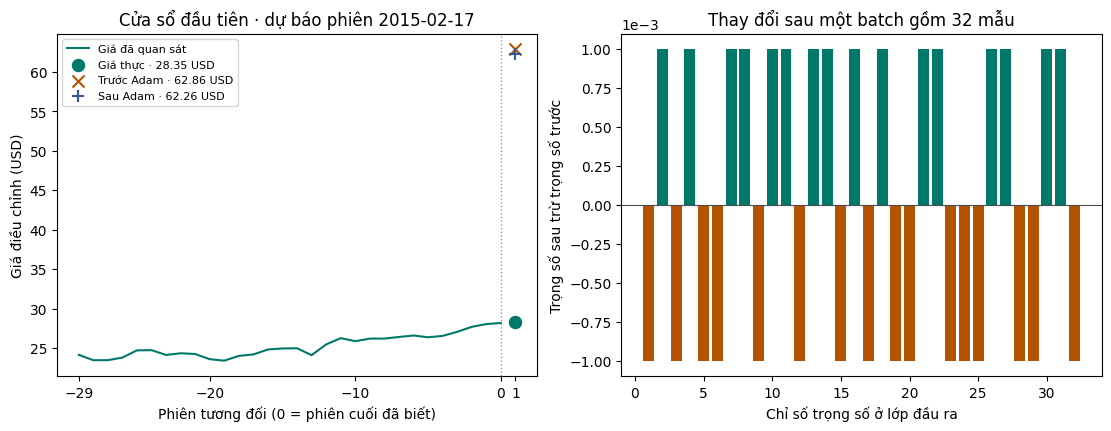

In [9]:
window = inverse_scale(x[0, :, 0].numpy(), demo_scaler)
actual, before, after = inverse_scale(np.array([y[0, 0].item(), prediction_before, prediction_after]), demo_scaler)
delta = (batch_model.fc.weight.detach() - weights_before).flatten().numpy()
fig, (ax, weights_ax) = plt.subplots(1, 2, figsize=(11, 4.2), layout='constrained')
ax.plot(range(1 - len(window), 1), window, color='#00796b', label='Giá đã quan sát')
ax.axvline(0, color='0.6', linestyle=':', linewidth=1)
for price, label, marker, color in [(actual, 'Giá thực', 'o', '#00796b'),
                                    (before, 'Trước Adam', 'x', '#b35300'),
                                    (after, 'Sau Adam', '+', '#34599a')]:
    ax.scatter(1, price, marker=marker, color=color, s=75, label=f'{label} · {price:.2f} USD')
ax.set(xlabel='Phiên tương đối (0 = phiên cuối đã biết)', ylabel='Giá điều chỉnh (USD)',
       title=f'Cửa sổ đầu tiên · dự báo phiên {demo_train.dataset.target_dates[0][0]}',
       xticks=[1 - len(window), -20, -10, 0, 1])
ax.legend(fontsize=8)
weights_ax.bar(range(1, len(delta) + 1), delta, color=np.where(delta >= 0, '#00796b', '#b35300'))
weights_ax.axhline(0, color='0.3', linewidth=0.8)
weights_ax.set(xlabel='Chỉ số trọng số ở lớp đầu ra', ylabel='Trọng số sau trừ trọng số trước',
               title=f'Thay đổi sau một batch gồm {len(y)} mẫu')
weights_ax.ticklabel_format(axis='y', style='sci', scilimits=(-3, -3))
show_figure(fig, '01_window_and_weights.png')

#### Từ batch đến epoch

Trong mỗi epoch, Adam cập nhật mô hình sau từng batch theo thứ tự thời gian. Ta ghi MSE của batch ngay trước lần cập nhật, rồi giữ cố định trọng số cuối epoch để dự báo toàn bộ validation. Các số được lấy trực tiếp khi hàm loss của trainer chạy.

In [10]:
demo_model = new_demo_model()
optimizer = torch.optim.Adam(demo_model.parameters(), lr=demo_lr)
history = []
batch_rows = []
validation_predictions = {}

def record_train_batch(module, inputs, loss):
    predictions, targets = inputs
    batch_rows.append({'Epoch': epoch, 'Batch': len(batch_rows) % len(demo_train) + 1,
                       'Samples': len(targets), 'MSE': loss.item()})

def record_validation_batch(module, inputs, loss):
    predictions, targets = inputs
    val_outputs.append(predictions.detach().clone())
    val_targets.append(targets.detach().clone())

for epoch in range(1, 6):
    with criterion.register_forward_hook(record_train_batch):
        train_loss = _run_epoch(demo_model, demo_train, criterion, optimizer)
    val_outputs, val_targets = [], []
    with criterion.register_forward_hook(record_validation_batch):
        val_loss = _run_epoch(demo_model, demo_val, criterion)
    predictions = torch.cat(val_outputs)
    targets = torch.cat(val_targets)
    assert torch.equal(targets, demo_val.dataset.y)
    np.testing.assert_allclose((predictions - targets).square().mean().item(), val_loss)
    validation_predictions[epoch] = predictions[:, 0].numpy()
    history.append({'Epoch': epoch, 'Train MSE': train_loss, 'Validation MSE': val_loss})
    print(f'Epoch {epoch}/5   Train MSE {train_loss:.6f}   Validation MSE {val_loss:.6f}', flush=True)
demo_history = pd.DataFrame(history).set_index('Epoch')
batches = pd.DataFrame(batch_rows)
for epoch, group in batches.groupby('Epoch'):
    assert len(group) == len(demo_train) and group['Samples'].sum() == len(demo_train.dataset)
    np.testing.assert_allclose(np.average(group['MSE'], weights=group['Samples']), demo_history.loc[epoch, 'Train MSE'])
batches.to_csv(demo_dir / 'train_batches.csv', index=False)
demo_history.to_csv(demo_dir / 'history.csv')
print('Đã lưu lịch sử epoch tại', (demo_dir / 'history.csv').relative_to(ROOT))
display(demo_history)

Epoch 1/5   Train MSE 0.829366   Validation MSE 3.071926


Epoch 2/5   Train MSE 0.099275   Validation MSE 0.127529


Epoch 3/5   Train MSE 0.203992   Validation MSE 0.607479


Epoch 4/5   Train MSE 0.040070   Validation MSE 0.256816


Epoch 5/5   Train MSE 0.041082   Validation MSE 0.179933


Đã lưu lịch sử epoch tại logs\audit\tv4_training_demo_20261125T130622448612Z\history.csv


,Train MSE,Validation MSE
Epoch,,
1,0.829366,3.071926
2,0.099275,0.127529
3,0.203992,0.607479
4,0.040070,0.256816
5,0.041082,0.179933


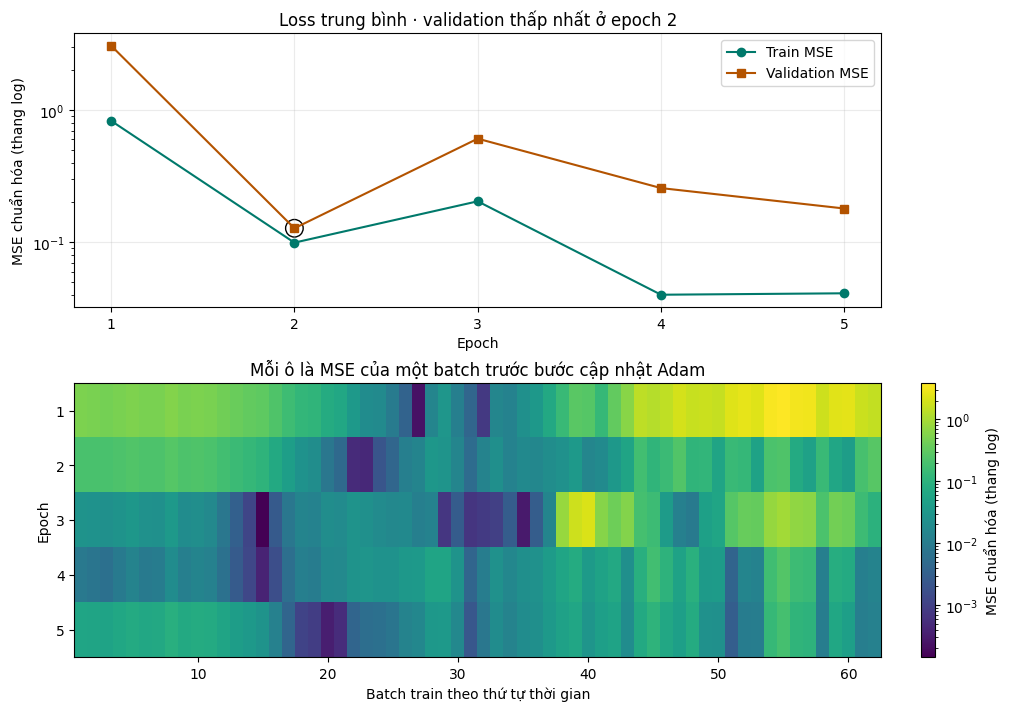

Đọc theo hàng để theo dõi từng lần cập nhật trong một epoch. Đọc theo cột để so cùng nhóm cửa sổ qua 5 epoch.
Ô sáng hơn biểu thị sai số lớn hơn. Các batch liên tiếp chứa các phiên khác nhau.


In [11]:
epochs = demo_history.index.to_list()
best = demo_history['Validation MSE'].idxmin()
fig, (curve, heat) = plt.subplots(2, 1, figsize=(10, 7), layout='constrained')
for name, color, marker in [('Train MSE', '#00796b', 'o'), ('Validation MSE', '#b35300', 's')]:
    curve.plot(epochs, demo_history[name], color=color, marker=marker, label=name)
curve.scatter(best, demo_history.loc[best, 'Validation MSE'], s=160, facecolors='none', edgecolors='black')
curve.set(yscale='log', xticks=epochs, xlabel='Epoch', ylabel='MSE chuẩn hóa (thang log)',
          title=f'Loss trung bình · validation thấp nhất ở epoch {best}')
curve.grid(alpha=0.25)
curve.legend()
matrix = batches.pivot(index='Epoch', columns='Batch', values='MSE')
batch_image = heat.imshow(matrix.clip(lower=1e-12), norm=LogNorm(), cmap='viridis',
                          interpolation='nearest', aspect='auto',
                          extent=(0.5, len(demo_train) + 0.5, epochs[-1] + 0.5, 0.5))
heat.set(xlabel='Batch train theo thứ tự thời gian', ylabel='Epoch', yticks=epochs,
         title='Mỗi ô là MSE của một batch trước bước cập nhật Adam')
fig.colorbar(batch_image, ax=heat, label='MSE chuẩn hóa (thang log)')
show_figure(fig, '02_epoch_and_batch_loss.png')
print('Đọc theo hàng để theo dõi từng lần cập nhật trong một epoch. Đọc theo cột để so cùng nhóm cửa sổ qua 5 epoch.')
print('Ô sáng hơn biểu thị sai số lớn hơn. Các batch liên tiếp chứa các phiên khác nhau.')

#### Mô hình dự báo cao hay thấp trên từng phiên validation?

Hai biểu đồ dùng cùng các ngày target năm 2023. Đường giá đối chiếu thực tế với dự báo của epoch có validation MSE nhỏ nhất trong lần minh họa và epoch cuối. Phía dưới, mỗi ô ứng với một epoch và một phiên. Sai số bằng **dự báo trừ thực tế** theo USD. Xanh là dự báo thấp, đỏ là dự báo cao, trắng là gần đúng. Mỗi cột cho phép theo dõi cùng một phiên khi trọng số thay đổi.

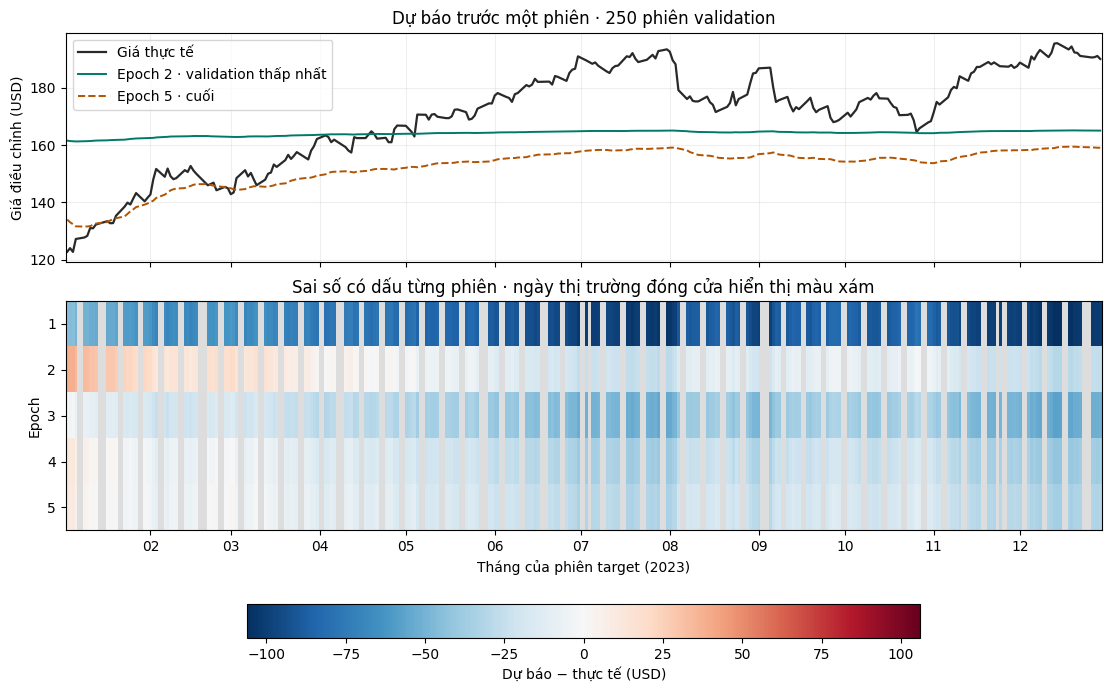

Epoch 2 dự báo thấp hơn thực tế ở 171/250 phiên validation.
Kết quả mô tả một lần chạy 5 epoch với seed 42
Hình PNG và dữ liệu từng batch, từng phiên được lưu tại logs\audit\tv4_training_demo_20261125T130622448612Z


In [12]:
import matplotlib.dates as mdates
dates = pd.DatetimeIndex(pd.to_datetime([target[0] for target in demo_val.dataset.target_dates]))
assert dates.is_unique and dates.is_monotonic_increasing and (dates.year == 2023).all()
actual_usd = inverse_scale(demo_val.dataset.y[:, 0].numpy(), demo_scaler)
val_prices = pd.DataFrame({epoch: inverse_scale(validation_predictions[epoch], demo_scaler)
                           for epoch in epochs}, index=dates)
val_prices.rename_axis('target_date').add_prefix('epoch_').assign(actual_usd=actual_usd).to_csv(demo_dir / 'validation_usd.csv')
errors = val_prices.sub(actual_usd, axis='index')

fig, (price_ax, error_ax) = plt.subplots(2, 1, figsize=(11, 6.8), sharex=True, layout='constrained')
price_ax.plot(dates, actual_usd, label='Giá thực tế', color='0.16', linewidth=1.6)
for epoch in dict.fromkeys([best, epochs[-1]]):
    label = f'Epoch {epoch}' + (' · validation thấp nhất' if epoch == best else ' · cuối')
    price_ax.plot(dates, val_prices[epoch], label=label, linewidth=1.4,
                  color='#00796b' if epoch == best else '#b35300', linestyle='-' if epoch == best else '--')
price_ax.set(ylabel='Giá điều chỉnh (USD)', title=f'Dự báo trước một phiên · {len(dates)} phiên validation')
price_ax.grid(alpha=0.2)
price_ax.legend()
# Vẽ mỗi phiên rộng một ngày để cuối tuần và ngày nghỉ giữ đúng khoảng trống.
calendar = pd.date_range(dates.min(), dates.max(), freq='D')
values = errors.reindex(calendar).to_numpy().T
limit = np.nanmax(np.abs(values)) or 1.0
image = error_ax.imshow(values, aspect='auto', interpolation='nearest', cmap='RdBu_r', vmin=-limit, vmax=limit,
                        extent=(mdates.date2num(calendar[0])-0.5, mdates.date2num(calendar[-1])+0.5,
                                epochs[-1]+0.5, 0.5))
error_ax.set_facecolor('#dddddd')
error_ax.set(yticks=epochs, ylabel='Epoch', xlabel='Tháng của phiên target (2023)',
             title='Sai số có dấu từng phiên · ngày thị trường đóng cửa hiển thị màu xám')
error_ax.xaxis.set_major_locator(mdates.MonthLocator())
error_ax.xaxis.set_major_formatter(mdates.DateFormatter('%m'))
fig.colorbar(image, ax=error_ax, orientation='horizontal', shrink=0.65, pad=0.12, label='Dự báo − thực tế (USD)')
show_figure(fig, '03_validation_prices_and_errors.png')
print(f'Epoch {best} dự báo thấp hơn thực tế ở {(errors[best] < 0).sum()}/{len(dates)} phiên validation.')
print('Kết quả mô tả một lần chạy 5 epoch với seed', demo_seed)
print('Hình PNG và dữ liệu từng batch, từng phiên được lưu tại', demo_dir.relative_to(ROOT))

## 4. Nghiệm thu vòng huấn luyện và quản lý run

Mục 3.1 dùng 5 epoch để quan sát. Ở đây trainer đọc cấu hình tối đa 100 epoch và patience 10. Để kiểm tra cả batch cuối chỉ có một mẫu, dùng 33 cửa sổ đầu của train và 33 cửa sổ đầu của validation từ bộ AAPL một bước. Con số MSE của phép thử chỉ mô tả các cửa sổ này.

Bảng ghi lại từng epoch từ CSV trên đĩa. Hãy tìm epoch có validation MSE nhỏ nhất, rồi so với epoch dừng. Sau khi trainer khôi phục trọng số tốt nhất trong RAM, script dự báo lại 33 mẫu validation và đối chiếu MSE tính trực tiếp với giá trị đã ghi. Có thể chạy riêng từ cell kế tiếp bằng kernel TV4.

In [13]:
from pathlib import Path
import sys
from datetime import datetime, timezone

cwd = Path.cwd().resolve()
ROOT = next((folder for folder in (cwd, *cwd.parents)
             if (folder / 'rule.md').is_file() and (folder / 'backend/training/trainer.py').is_file()), None)
if ROOT is None:
    raise RuntimeError(f'Hãy mở notebook trong thư mục project. Thư mục kernel hiện tại là {cwd}')
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

import json
import subprocess
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

probe = subprocess.run([sys.executable, '-X', 'utf8', str(ROOT / 'scripts/check_tv4_training_run.py')],
                       cwd=ROOT, capture_output=True, text=True, encoding='utf-8')
if probe.returncode:
    raise RuntimeError(probe.stderr or probe.stdout)
evidence = Path(json.loads(probe.stdout)['evidence'])
item4 = json.loads(evidence.read_text(encoding='utf-8'))
assert item4['passed']
run_dir = ROOT / item4['run_dir']
meta = json.loads((run_dir / 'metadata.json').read_text(encoding='utf-8'))
epochs4 = pd.read_csv(run_dir / 'epoch_logs.csv')
display(pd.DataFrame(item4['splits']))
display(epochs4)
display(pd.DataFrame([{'Seed': meta['seed'], 'CPU threads': meta['torch_threads'], 'Trạng thái': meta['status'],
                       'Epoch tốt nhất': item4['best_epoch'], 'Epoch cuối': item4['epochs'],
                       'Dừng sớm': item4['early_stopped'], 'MSE tốt nhất': item4['best_val_loss'],
                       'MSE đo lại từ RAM': item4['restored_val_mse']}]))
print('Log và cấu hình của run:', run_dir)
print('Biên bản kiểm chứng:', evidence)

,split,samples,first_target,last_target
0,train,33,2015-02-17,2015-04-02
1,validation,33,2023-01-03,2023-02-17


,epoch,train_loss,val_loss,learning_rate,time_seconds,train_seconds,validation_seconds,val_mse_per_horizon
0,1,0.510358,2.521352,0.001,0.235179,0.217322,0.017854,[2.5213520671710237]
1,2,0.475284,2.539462,0.001,0.083329,0.066483,0.016844,[2.539462248850127]
2,3,0.440778,2.557887,0.001,0.092124,0.068851,0.023272,[2.5578874796158413]
3,4,0.406720,2.576755,0.001,0.071257,0.059628,0.011628,[2.5767553444281504]
4,5,0.372858,2.596429,0.001,0.056116,0.043654,0.012461,[2.5964285620466185]
5,6,0.338905,2.617374,0.001,0.060439,0.047222,0.013216,[2.6173737526330703]
6,7,0.304613,2.640041,0.001,0.057060,0.044127,0.012932,[2.6400413032333487]
7,8,0.269761,2.664844,0.001,0.051092,0.041932,0.009159,[2.66484426384911]
8,9,0.234168,2.692149,0.001,0.070744,0.056435,0.014308,[2.6921489353712715]
9,10,0.197743,2.722289,0.001,0.066066,0.050214,0.015851,[2.722289200154424]


,Seed,CPU threads,Trạng thái,Epoch tốt nhất,Epoch cuối,Dừng sớm,MSE tốt nhất,MSE đo lại từ RAM
0,42,1,completed,1,11,True,2.521352,2.521352


Log và cấu hình của run: D:\learn_DeepLearning\Project_course-work\logs\audit\tv4_item4_20261125T130707150172Z\runs\lstm_one_step__item4_first33_ram__seed42__20261125_200834_397397
Biên bản kiểm chứng: D:\learn_DeepLearning\Project_course-work\logs\audit\tv4_item4_20261125T130707150172Z\summary.json


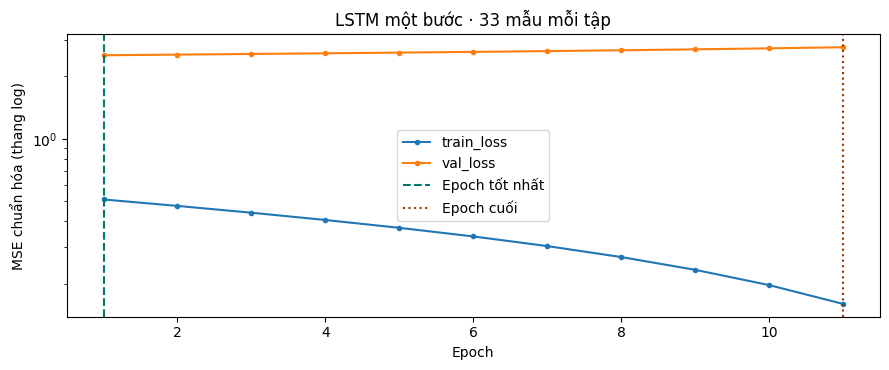

In [14]:
ax = epochs4.plot(x='epoch', y=['train_loss', 'val_loss'], marker='.', figsize=(9, 3.8))
ax.set_yscale('log')
ax.axvline(item4['best_epoch'], color='#00796b', linestyle='--', label='Epoch tốt nhất')
ax.axvline(item4['epochs'], color='#933700', linestyle=':', label='Epoch cuối')
ax.set(xlabel='Epoch', ylabel='MSE chuẩn hóa (thang log)', title='LSTM một bước · 33 mẫu mỗi tập')
ax.legend()
plt.tight_layout()
plt.show()

## 5. Lưu checkpoint và nạp model mới

        Runner lưu một thư mục mới cho mỗi lần validation cải thiện. Manifest ghi seed, cấu hình, epoch, loss, snapshot, scaler và năm hash nguồn. Phép thử dùng 33 cửa sổ mỗi tập của LSTM một bước. Model nạp từ đĩa phải dự báo bằng tuyệt đối model tốt nhất trong RAM trên toàn bộ 33 mẫu validation.

In [15]:
from pathlib import Path
import sys
from datetime import datetime, timezone

cwd = Path.cwd().resolve()
ROOT = next((folder for folder in (cwd, *cwd.parents)
             if (folder / 'rule.md').is_file() and (folder / 'backend/training/trainer.py').is_file()), None)
if ROOT is None:
    raise RuntimeError(f'Hãy mở notebook trong thư mục project. Thư mục kernel hiện tại là {cwd}')
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

import subprocess, json
import pandas as pd
from IPython.display import display
run5 = subprocess.run([sys.executable, '-X', 'utf8', str(ROOT / 'scripts/check_tv4_training_run.py'), '--checkpoint'],
                      cwd=ROOT, capture_output=True, text=True, encoding='utf-8')
if run5.returncode:
    raise RuntimeError(run5.stderr or run5.stdout)
path5 = Path(json.loads(run5.stdout)['evidence'])
result5 = json.loads(path5.read_text(encoding='utf-8'))
assert result5['passed'] and result5['reload_verified']
display(pd.DataFrame([result5]))
print('Checkpoint:', result5['checkpoint_path'])
print('Bằng chứng:', path5)

,passed,scope,splits,run_id,run_dir,best_epoch,epochs,best_val_loss,restored_val_mse,early_stopped,patience,checkpoint_path,reload_verified
0,True,"one-step AAPL subset, disk reload","[{'split': 'train', 'samples': 33, 'first_targ...",lstm_one_step__item5_first33_reload__seed42__2...,logs/audit/tv4_item5_20261125T130918957790Z/ru...,1,11,2.521352,2.521352,True,10,D:\learn_DeepLearning\Project_course-work\arti...,True


Checkpoint: D:\learn_DeepLearning\Project_course-work\artifacts\checkpoints\tv4_item5_20261125T130918957790Z\lstm_one_step__item5_first33_reload__seed42__20261125_200939_315240__epoch1
Bằng chứng: D:\learn_DeepLearning\Project_course-work\logs\audit\tv4_item5_20261125T130918957790Z\summary.json


<a id="tv4-item-6"></a>

        ## 6. Smoke training hai horizon và đo CPU

        Chạy ba epoch trên toàn bộ train và validation cho mỗi LSTM, seed 42, một luồng tính toán, CPU float64. Lưu checkpoint theo validation rồi nạp model mới và so toàn bộ dự báo validation bằng dung sai 0. Đo riêng train, validation và 30 lượt inference batch sau 5 lượt làm nóng. Thời gian phụ thuộc máy và tải nền. Các kết quả thuộc lần chạy chẩn đoán giới hạn ba epoch.

,model,horizon,seed,train_samples,val_samples,parameters,epochs,best_epoch,best_val_mse,val_mse_per_horizon,...,train_seconds,validation_seconds,inference_batch_samples,inference_repeats,warmup,inference_batch_median_ms,total_seconds,reload_equal,run_dir,checkpoint
0,one_step,1,42,1984,250,4513,3,2,0.127529,[0.12752890491451985],...,2.415032,0.086208,32,30,5,1.7828,34.031066,True,D:\learn_DeepLearning\Project_course-work\logs...,D:\learn_DeepLearning\Project_course-work\arti...
1,multi_step,5,42,1980,246,4645,3,3,0.787665,"[0.8107571160297916, 0.72875451622755, 0.74904...",...,4.276999,0.201545,32,30,5,7.4876,22.962617,True,D:\learn_DeepLearning\Project_course-work\logs...,D:\learn_DeepLearning\Project_course-work\arti...


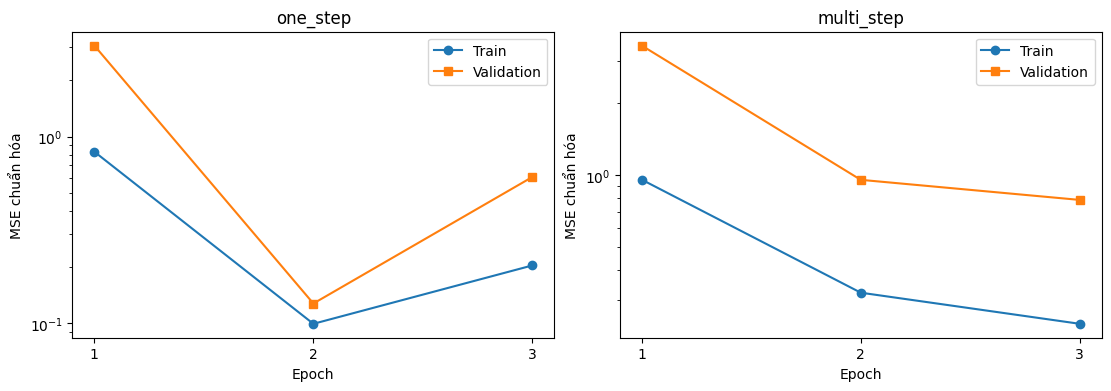

Bằng chứng và điều kiện CPU: D:\learn_DeepLearning\Project_course-work\logs\audit\tv4_item6_20261125T131000327361Z\summary.json
Threads: 1 | CPU: Intel64 Family 6 Model 140 Stepping 1, GenuineIntel


In [16]:
from pathlib import Path
import sys
from datetime import datetime, timezone

cwd = Path.cwd().resolve()
ROOT = next((folder for folder in (cwd, *cwd.parents)
             if (folder / 'rule.md').is_file() and (folder / 'backend/training/trainer.py').is_file()), None)
if ROOT is None:
    raise RuntimeError(f'Hãy mở notebook trong thư mục project. Thư mục kernel hiện tại là {cwd}')
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

import subprocess, json
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
smoke = subprocess.run([sys.executable, '-X', 'utf8', str(ROOT / 'scripts/check_tv4_smoke.py')],
                       cwd=ROOT, capture_output=True, text=True, encoding='utf-8')
if smoke.returncode:
    raise RuntimeError(smoke.stderr or smoke.stdout)
receipt6 = Path(json.loads(smoke.stdout)['evidence'])
item6 = json.loads(receipt6.read_text(encoding='utf-8'))
assert item6['passed'] and all(row['reload_equal'] for row in item6['results'])
display(pd.DataFrame(item6['results']))
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8), layout='constrained')
for ax, row in zip(axes, item6['results']):
    history6 = pd.read_csv(Path(row['run_dir']) / 'epoch_logs.csv')
    ax.plot(history6.epoch, history6.train_loss, marker='o', label='Train')
    ax.plot(history6.epoch, history6.val_loss, marker='s', label='Validation')
    ax.set(title=row['model'], xlabel='Epoch', ylabel='MSE chuẩn hóa', xticks=history6.epoch, yscale='log')
    ax.legend()
plt.show()
print('Bằng chứng và điều kiện CPU:', receipt6)
print('Threads:', item6['threads'], '| CPU:', item6['cpu'])

<a id="tv4-item-7"></a>

        ## 7. Audit thiết kế và ngân sách thực nghiệm

        Pipeline đã mở rộng lookback 10/30/60, giữ mặc định 30 cho callers cũ. Kế hoạch gồm 12 run, seeds 42/123/456, tối đa 100 epoch mỗi run. Báo cáo bên dưới ghi bằng chứng và các quy tắc trước training chính thức.

In [17]:
from pathlib import Path
import sys
from datetime import datetime, timezone

cwd = Path.cwd().resolve()
ROOT = next((folder for folder in (cwd, *cwd.parents)
             if (folder / 'rule.md').is_file() and (folder / 'backend/training/trainer.py').is_file()), None)
if ROOT is None:
    raise RuntimeError(f'Hãy mở notebook trong thư mục project. Thư mục kernel hiện tại là {cwd}')
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

from IPython.display import display, Markdown
display(Markdown((ROOT / 'reports/audits/TV4_Item7_Experiment_Plan.md').read_text(encoding='utf-8')))

# TV4 mục 7 — audit và thiết kế thực nghiệm

## Đối chiếu thông số cuối trước training

Đã đọc lại bốn YAML chính thức từ summary mục 7, xác minh SHA256 của scaler/prepared manifest và toàn bộ payload prepared. Đối chiếu target dates train 2015–2022, validation 2023, dtype float64, shape và số tham số model. Cả bốn cấu hình đạt. Một bước lookback 10/30/60 có cùng 1.954 mẫu train, 250 mẫu validation và 4.513 tham số. Năm bước lookback 30 có 1.980 mẫu train, 246 mẫu validation, 4.645 tham số.

Cấu hình chung là hidden 32, một lớp, một feature, Adam 0,001, batch 32, MSE, max_epochs 100, patience 10, clipping tắt, một luồng CPU và seeds 42/123/456. Output năm bước được factory suy ra từ forecast_length=5 dù YAML không ghi output_size. Bản YAML baseline một bước ở experiments/configs dùng đầy đủ 1.984 mẫu train; chạy thực nghiệm lookback phải dùng bốn YAML được liệt kê trong summary mục 7 để giữ đúng common target dates.

Điều kiện chạy đã sẵn sàng cho kế hoạch 12 run. Đợt đối chiếu này kiểm cấu hình và artifacts, không chạy huấn luyện. [Biên bản thông số cuối](../../logs/audit/tv4_pretrain_20261125T122223473143Z/summary.json)

## Hoàn thiện theo yêu cầu trước training

Kế hoạch mục 7 đã chốt cho 12 run, tối đa 1.200 epoch. Ba lookback một bước dùng cùng 1.954 mẫu train và 250 mẫu validation. Bốn cấu hình đã qua probe một epoch và kiểm CSV diagnostics. Hồi quy TV2/TV4/checkpoint đạt 128 tests, 96 subtests. Strict TV4 đạt 67/67 trong môi trường sạch. [Bằng chứng kế hoạch](../../logs/audit/tv4_item7_20261125T120957429763Z/summary.json) · [JUnit hồi quy](../../logs/audit/tv4_item7_20261125T120957429763Z/regression.xml) · [Strict TV4](../../logs/audit/tv4_tests_20261125T121649383002Z/summary.json)

Đã nạp mới cả bốn checkpoint của probe, đo lại validation MSE và đối chiếu với best loss đã lưu trong metadata, dung sai tương đối 1e-12. Summary ghi all_four_reload_mse_verified=true.

Khi TV5 so CNN với LSTM lookback 30, dùng cùng 1.954 mẫu train và 250 mẫu validation của nhóm common60 cùng các khóa mẫu đánh giá. Nếu dùng toàn bộ 1.984 mẫu train cho CNN phải tạo lại run đối ứng LSTM và ghi ngân sách bổ sung trước khi chạy. CNN cụ thể và ngân sách riêng vẫn thuộc nhiệm vụ TV5.

Runner strict giữ receipt intake gốc và đối chiếu riêng hash của các file TV2 được thay đổi theo yêu cầu mục 7 tại TV4_Item7_Source_Changes.json. Artifacts nguồn vẫn đối chiếu hash ban đầu. Những dòng ghi chờ hoặc chưa hỗ trợ bên dưới là audit trước khi thực hiện các sửa đổi này.

Theo yêu cầu người dùng hoàn thiện toàn bộ các việc audit, đã mở rộng pipeline 10/30/60. Cấu hình cũ mặc định 30 và artifacts gốc giữ nguyên. Artifacts mới kiểm coverage đầy đủ từng lookback trước khi chọn chung target có đủ 60 phiên lịch sử. Kế hoạch chính thức gồm 9 run một bước trên ba lookback và ba seed, cộng 3 run năm bước tại lookback 30. Tổng giới hạn 1.200 epoch. Chọn lookback bằng validation MSE trung bình ba seed, hòa đúng số lưu ưu tiên lookback ngắn hơn, báo std mẫu ddof=1.

Đã bổ sung hash toàn bộ backend và YAML vào metadata run và checkpoint, ghi cấu hình run, số luồng tính toán đặt mặc định 1 ở runner và tường minh trong YAML. CSV lưu train_seconds, validation_seconds và val_mse_per_horizon sau mỗi epoch. Khi checkpoint sau gặp lỗi, metrics vẫn giữ tham chiếu checkpoint trước đã ghi thành công. Giữ nguyên trạng thái failed/interrupted để tổng hợp run chính thức.

Runner tìm project root từ vị trí source, hỗ trợ YAML nằm trong thư mục audit. Lần probe đầu phát hiện đường dẫn sai và được ghi failed. Đã sửa đường dẫn trước chạy probe lại. Các kết quả failed giữ lại để truy vết.

Các phần audit ban đầu dưới đây mô tả trạng thái trước sửa và lý do thay đổi. Phiên bản hoàn thiện có bằng chứng ở logs/audit/tv4_item7_20261125T120957429763Z, gồm bốn cấu hình chính thức, artifacts tham chiếu, regression.xml và các probe một epoch.

## Tái kiểm tra trước training ngày 25/11/2026

Lượt mới chạy strict tests đạt 66/66, không skip, môi trường sạch và import đúng workspace. Kiểm tra lại AAPL cho cả hai horizon đạt, gồm provenance/hash, ngày, số mẫu và forward CPU float64. [Tests](../../logs/audit/tv4_tests_20261125T120434712517Z/summary.json) · [Dữ liệu thật](../../logs/audit/tv4_item3_20261125T120532955439Z/summary.json)

Kết luận sẵn sàng kỹ thuật cho pipeline lookback 30 đã smoke ở mục 6. Thiết kế toàn bộ thực nghiệm vẫn chờ khóa. Những việc cần hoàn tất trước run chính thức gồm phạm vi lookback 10/60, hash đầy đủ source model/transforms và YAML, lưu validation từng horizon cho run năm bước, và đặt rõ số luồng CPU ở entry point chạy chính thức. Runner chỉ ghi số luồng hiện có, script smoke mới trực tiếp đặt một luồng.

CSV hiện bỏ hai trường train_seconds/validation_seconds có trong kết quả trainer. Nếu cần tái lập bảng đo riêng cho run chính thức, cần lưu thêm các trường này hoặc summary riêng như smoke đã làm. Khi ghi checkpoint lỗi, CSV có epoch đã quan sát nhưng metadata lỗi chưa giữ đường dẫn checkpoint trước đó. Trạng thái failed giúp tránh coi run ấy là hoàn tất, cần bổ sung tham chiếu best đã lưu khi hoàn thiện nghiệm thu run lỗi.

Giới hạn kiểm chứng của bộ 66 tests gồm các phép thử tổng hợp. Hai horizon reload trên AAPL dựa bằng chứng mục 6, lượt tái kiểm này chạy lại data acceptance và tests, không chạy huấn luyện chính thức.

Ngày 25/11/2026. Phương án ban đầu và lịch sử audit được giữ bên dưới để đối chiếu với phần cập nhật hoàn thiện phía trên.

## Cơ sở kiểm tra

Đối chiếu rule.md, đề Topic 4, tài liệu nền mục 8–12, ranh giới và contract, phân công TV4, Decision Log và Open Decisions. Kiểm tra source factory, windowing, prepared artifacts, trainer, runner và bằng chứng mục 6. Đề gốc yêu cầu next-day LSTM cùng mở rộng multi-step và CNN. AAPL, lookback, seed và ngân sách là thiết kế nhóm.

## Kết quả audit

| Nội dung | Bằng chứng và kết luận |
|---|---|
| Nối dữ liệu và dtype | Hai horizon dùng snapshot/scaler/prepared có provenance, CPU float64 |
| Checkpoint | Smoke ba epoch nạp model mới, dự báo toàn validation bằng best trong RAM |
| Seed | Hai YAML có 42, 123, 456. Quy trình chính thức cần giữ cả ba và báo đầy đủ |
| Lookback | factory yêu cầu 30, windows.py cắt 30 phiên, prepared.py ghi và kiểm 30. Model hỗ trợ shape 10/60 chưa chứng minh pipeline hỗ trợ |
| Thời gian | Run mục 6 đo một luồng tính toán, interop 2. One-step train+validation ba epoch 6,210 giây, five-step 6,556 giây |
| Lịch sử | CSV lưu train/val/LR/thời gian tổng epoch. Trường thời gian train/validation mới trong kết quả RAM, summary smoke lưu tổng riêng |
| Hash nguồn | Metadata run ghi runner/manager/trainer/factory và provenance. Chưa có hash đầy đủ model/scaler transform hoặc config YAML như một manifest nghiệm thu cuối |
| Lỗi/ngắt | Exception và KeyboardInterrupt được ghi trạng thái. Kill cưỡng bức có thể để trạng thái running, cần kiểm run chưa hoàn tất khi tổng hợp |
| CNN | Kiến trúc/ngân sách CNN còn mở, cần quy tắc so sánh TV5 trước kết luận |
| Tập test | Đánh giá sau khi khóa cấu hình và quy tắc, TV6 chịu trách nhiệm |

## Đề xuất cấu hình cố định cho lookback 30

Hai LSTM một lớp hidden 32, một đặc trưng adjusted close. Output 1 và 5. CPU float64, một luồng tính toán và ghi số interop thực tế. Batch 32 giữ batch cuối, thứ tự thời gian, Adam learning rate 0,001, MSE, tối đa 100 epoch, patience 10. Giữ gradient clipping tắt theo cấu hình hiện có. Dừng và ghi lỗi nếu loss/gradient/trọng số không hữu hạn.

Train target 2015–2022, validation target 2023. Giữ scaler train của TV2 và các ID/hash đã ghim trong hai YAML. Checkpoint chọn bằng validation MSE nhỏ hơn nghiêm ngặt, hòa giữ epoch sớm hơn. MSE năm bước trung bình đều trên năm horizon. Đo lại loss từ model nạp từ đĩa.

Ngân sách chính gồm 2 horizon × 3 seed = 6 run, tối đa 600 epoch. Không mở lưới hidden size/LR trong kế hoạch này. Báo từng seed, trung bình và độ lệch chuẩn mẫu ddof=1. Trung bình các seed mô tả nhiều lần huấn luyện độc lập.

Nội suy đơn giản từ smoke 30 phiên cho 600 epoch là khoảng 1.277 giây, tương đương 21,3 phút train+validation. Đây là ước lượng để lập kế hoạch. Thời gian xác minh artifacts, ghi checkpoint, reload, tải nền và biến động hiệu năng làm tổng thực tế khác đi. Early stopping có thể giảm số epoch.

## Kế hoạch lookback cần thống nhất

Đề xuất giữ so sánh độ nhạy 10/30/60 cho LSTM một bước, mỗi lookback ba seed, cùng cấu hình và tối đa 100 epoch. Tổng 9 run một bước cộng 3 run năm bước tại lookback 30 là 12 run, tối đa 1.200 epoch. Các run lookback 30 dùng chung nếu đúng cùng tập mẫu và cấu hình, tránh đếm hai lần.

Để thực hiện cần bổ sung contract TV2 cho windowing/prepared 10/60, tạo artifacts mới với ID riêng, dùng giao target dates hợp lệ ở từng split và cùng scaler train. Đếm lại mẫu, audit pairing và leakage trước training. Cấu hình lookback 30 đã chạy với toàn bộ mẫu có thể cần run riêng nếu giao ngày làm thay đổi tập train. Ngân sách khi đó phải cập nhật trước run.

Chọn lookback bằng validation MSE trung bình ba seed trên cùng mẫu. Nếu hòa đúng số lưu, ưu tiên lookback ngắn hơn. Giữ báo cáo baseline lookback 30 cho CNN theo tài liệu nền. Kết quả 10/60 còn phụ thuộc triển khai và đo thời gian riêng, chưa thể ngoại suy chắc chắn từ smoke lookback 30.

## Điều kiện trước các run chính thức

Thống nhất phần lookback trước khi ghi Decision Log thành kế hoạch đã chốt. Lưu cấu hình và hash nguồn đầy đủ theo từng run. Mỗi run có model khởi tạo mới, manifest checkpoint, lịch sử, điều kiện CPU và xác minh reload. Multi-step cần bảng validation từng horizon ở run chính thức. Phân biệt run lỗi với run hoàn tất khi tổng hợp.

Sau khi khóa cấu hình, TV6 đánh giá MAE/RMSE USD, baseline persistence và CNN trên cùng khóa mẫu. Mọi kết quả test từng được xem trước khi sửa phải được ghi vào giới hạn nghiên cứu. Báo cáo hiện chỉ xác nhận các bằng chứng train/validation đã đọc.

## Kết luận nghiệm thu

Mục 7 đã có audit và phương án ngân sách cụ thể. Việc khóa toàn bộ thiết kế còn phụ thuộc quyết định triển khai lookback 10/60. Chưa đánh dấu hoàn thành toàn bộ mục 7.

Nguồn đo CPU tại [summary mục 6](../../logs/audit/tv4_item6_20261125T115308089469Z/summary.json). Source kiểm tra tại backend/experiments/runner/aapl_factories.py, backend/data/preparation/windows.py và backend/artifacts/prepared.py.


<a id="tv4-item-8"></a>

        ## 8. Huấn luyện chính thức LSTM một bước

        Chín run dùng lookback 10/30/60 và seeds 42/123/456, cùng 1.954 mẫu train và 250 mẫu validation. Mỗi run tối đa 100 epoch, patience 10. Chọn lookback theo validation MSE trung bình ba seed, báo độ lệch chuẩn mẫu ddof=1. Cell đọc kết quả đã lưu để xem lại quá trình học.

        **Audit sau training.** Chín trạng thái run, best epoch và hash checkpoint đã đối chiếu đạt. Bốn run chạm 100 epoch, hai run có best ở epoch 100. Đây là giới hạn ngân sách cần ghi trong báo cáo. Dữ liệu thật và cấu hình LSTM năm bước đã kiểm tra lại, đủ điều kiện bước vào mục 9. Xem [báo cáo audit sau training](../reports/audits/TV4_Item8_OneStep_Training.md).

        Xem tương tác tại [TensorBoard local](http://127.0.0.1:6006) khi server đang chạy. Dashboard xuất từ CSV của chín run đã hoàn tất. Trục Step là epoch. Các nhóm Loss, Optimizer và Time hiển thị loss, learning rate và thời gian train/validation. Wall time của event là thời điểm xuất dữ liệu.

In [18]:
from pathlib import Path
import sys
from datetime import datetime, timezone

cwd = Path.cwd().resolve()
ROOT = next((folder for folder in (cwd, *cwd.parents)
             if (folder / 'rule.md').is_file() and (folder / 'backend/training/trainer.py').is_file()), None)
if ROOT is None:
    raise RuntimeError(f'Hãy mở notebook trong thư mục project. Thư mục kernel hiện tại là {cwd}')
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

import json
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown
item8_path = ROOT / 'logs/audit/tv4_item8_20261125T122649342552Z/summary.json'
item8 = json.loads(item8_path.read_text(encoding='utf-8'))
assert item8['passed'] and item8['status'] == 'completed'
results8 = pd.DataFrame(item8['results'])
assert len(results8) == 9 and results8.reload_verified.all()
display(results8[['lookback','seed','epochs','best_epoch','validation_mse','seconds','reload_verified']])
display(pd.DataFrame(item8['aggregates']))
print('Lookback được chọn theo validation trung bình:', item8['selected_lookback'])
print('Bằng chứng:', item8_path)

,lookback,seed,epochs,best_epoch,validation_mse,seconds,reload_verified
0,10,42,89,79,0.002993,42.063139,True
1,10,123,100,100,0.002720,48.728001,True
2,10,456,18,8,0.031023,7.815292,True
3,30,42,100,97,0.002462,117.651981,True
4,30,123,100,97,0.002792,158.453443,True
5,30,456,85,75,0.004544,250.127244,True
6,60,42,94,84,0.002815,218.425481,True
7,60,123,100,100,0.003524,238.192838,True
8,60,456,89,79,0.004350,185.536601,True


,lookback,mean_validation_mse,sample_std
0,10,0.012245,0.016262
1,30,0.003266,0.001119
2,60,0.003563,0.000769


Lookback được chọn theo validation trung bình: 30
Bằng chứng: D:\learn_DeepLearning\Project_course-work\logs\audit\tv4_item8_20261125T122649342552Z\summary.json


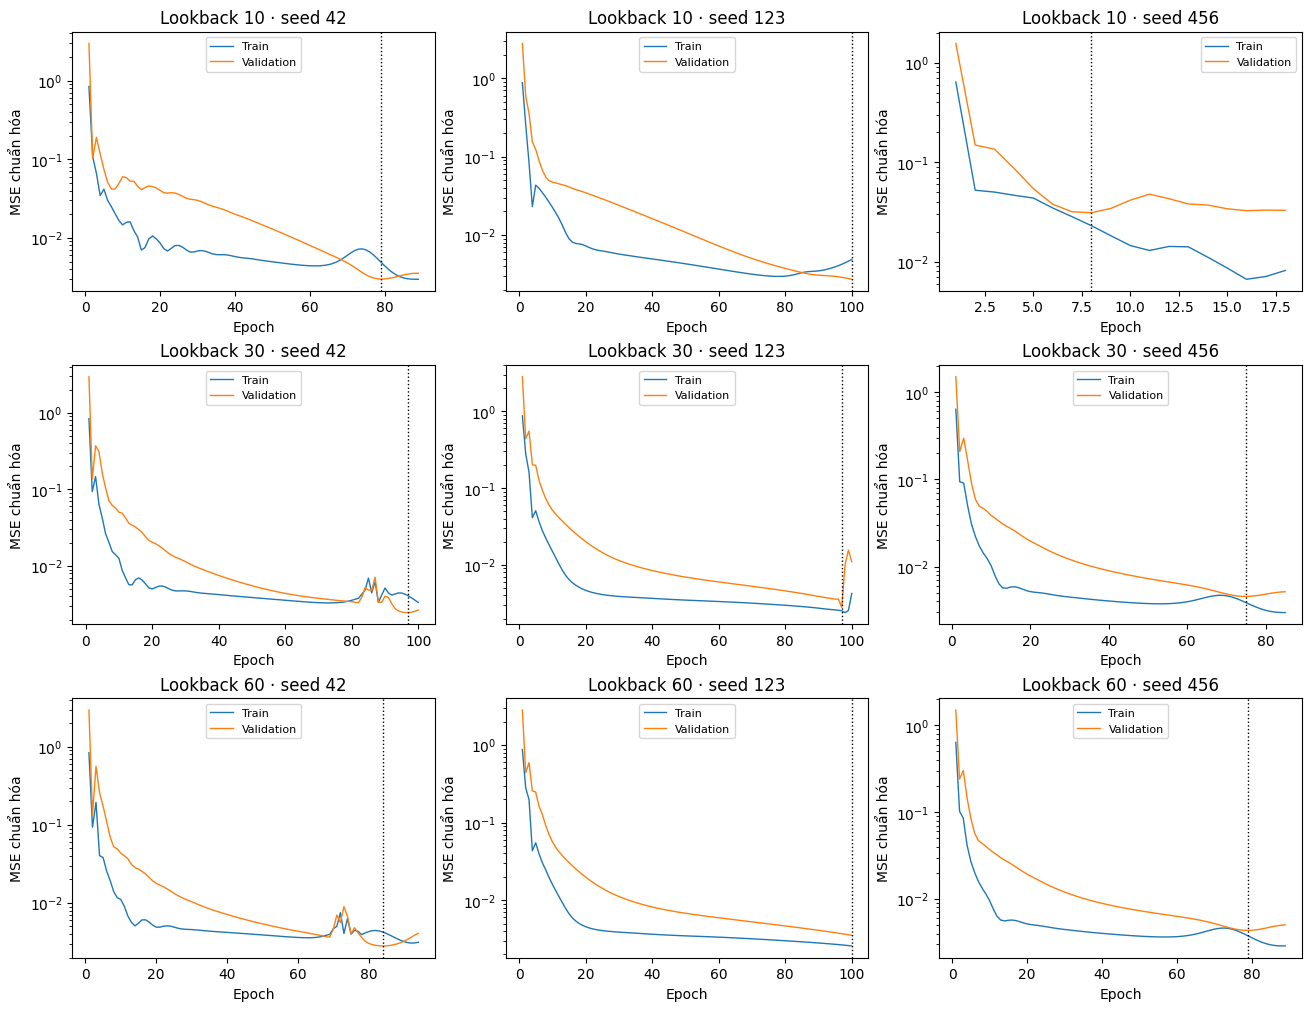

In [19]:
fig, axes = plt.subplots(3, 3, figsize=(13, 10), layout='constrained')
for ax, row in zip(axes.flat, item8['results']):
    history = pd.read_csv(Path(row['run_dir']) / 'epoch_logs.csv')
    ax.plot(history.epoch, history.train_loss, label='Train', linewidth=1)
    ax.plot(history.epoch, history.val_loss, label='Validation', linewidth=1)
    ax.axvline(row['best_epoch'], linestyle=':', color='black', linewidth=1)
    ax.set(title=f"Lookback {row['lookback']} · seed {row['seed']}",
           xlabel='Epoch', ylabel='MSE chuẩn hóa', yscale='log')
    ax.legend(fontsize=8)
fig.savefig(item8_path.parent / 'learning_curves.png', dpi=150)
plt.show()

<a id="tv4-item-9"></a>

        ## 9. Huấn luyện chính thức LSTM năm bước

        **Các vấn đề audit đã được xử lý ngày 26/11/2026.** Trainer yêu cầu callback lưu hợp lệ ngay từ đầu, tài liệu đã đồng bộ và có manifest đường dẫn tương đối. Hồi quy strict đạt 69/69, kiểm 323 file và nạp lại 12 model trên bản sao ở thư mục khác đạt. Xem [báo cáo sửa lỗi](../reports/audits/TV4_Audit_Fixes_20261126.md).

        Lookback 30, ba seed 42/123/456, 1.980 mẫu train và 246 mẫu validation. Mỗi mẫu có đủ năm target thuộc cùng tập. Mô hình xuất đồng thời năm giá, được chọn bằng MSE tổng trên năm bước có trọng số bằng nhau. Cấu hình tối đa 100 epoch, patience 10. Các bảng dưới đọc kết quả chính thức đã lưu.

In [1]:
from pathlib import Path
import sys
from datetime import datetime, timezone

cwd = Path.cwd().resolve()
ROOT = next((folder for folder in (cwd, *cwd.parents)
             if (folder / 'rule.md').is_file() and (folder / 'backend/training/trainer.py').is_file()), None)
if ROOT is None:
    raise RuntimeError(f'Hãy mở notebook trong thư mục project. Thư mục kernel hiện tại là {cwd}')
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

import json
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown
item9_path = ROOT / 'logs/audit/tv4_item9_20261125T140320407544Z/summary.json'
item9 = json.loads(item9_path.read_text(encoding='utf-8'))
assert item9['passed'] and item9['status'] == 'completed'
results9 = pd.DataFrame(item9['results'])
assert len(results9) == 3 and results9.reload_verified.all()
display(results9[['seed','epochs','best_epoch','validation_mse','seconds','reload_verified']])
display(pd.DataFrame(item9['aggregates']))
horizons9 = pd.DataFrame([row['validation_mse_per_horizon'] for row in item9['results']],
                        index=results9.seed, columns=[f'Bước {i}' for i in range(1,6)])
display(horizons9)
print('Bằng chứng:', item9_path)

,seed,epochs,best_epoch,validation_mse,seconds,reload_verified
0,42,100,100,0.007562,182.342666,True
1,123,100,100,0.007852,87.696792,True
2,456,100,100,0.007664,85.693393,True


,lookback,mean_validation_mse,sample_std
0,30,0.007693,0.000147


,Bước 1,Bước 2,Bước 3,Bước 4,Bước 5
seed,,,,,
42,0.003843,0.006236,0.007180,0.008779,0.011773
123,0.003952,0.005781,0.007567,0.009180,0.012779
456,0.003489,0.004858,0.007266,0.010401,0.012309


Bằng chứng: D:\learn_DeepLearning\Project_course-work\logs\audit\tv4_item9_20261125T140320407544Z\summary.json


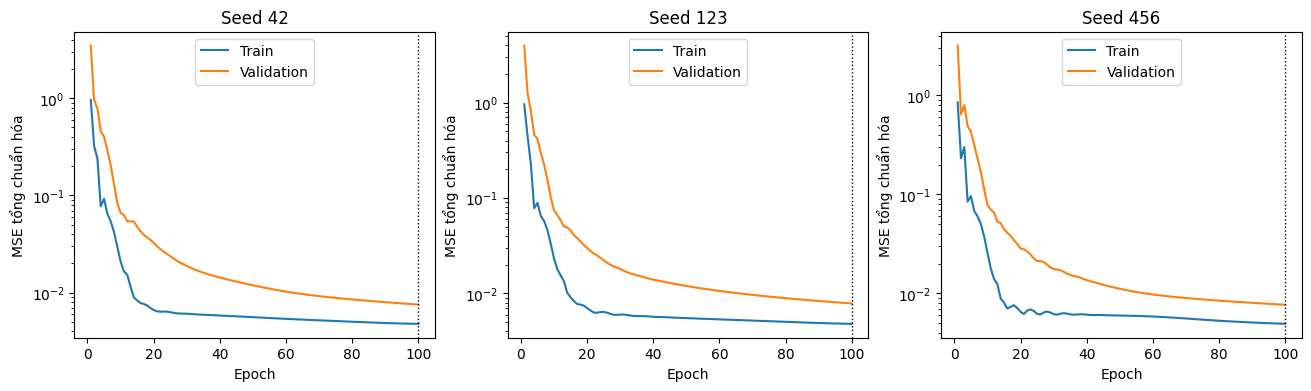

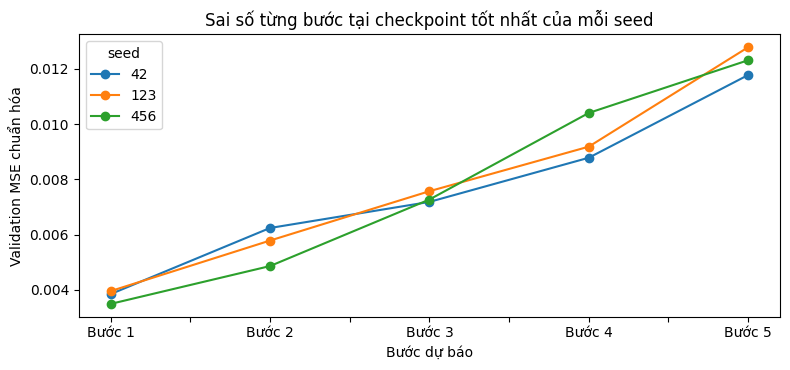

In [2]:
fig, axes = plt.subplots(1, 3, figsize=(13, 3.8), layout='constrained')
for ax, row in zip(axes, item9['results']):
    history = pd.read_csv(Path(row['run_dir']) / 'epoch_logs.csv')
    ax.plot(history.epoch, history.train_loss, label='Train')
    ax.plot(history.epoch, history.val_loss, label='Validation')
    ax.axvline(row['best_epoch'], color='black', linestyle=':', linewidth=1)
    ax.set(title=f"Seed {row['seed']}", xlabel='Epoch', ylabel='MSE tổng chuẩn hóa', yscale='log')
    ax.legend()
fig.savefig(item9_path.parent / 'learning_curves.png', dpi=150)
plt.show()
ax = horizons9.T.plot(marker='o', figsize=(8, 3.8))
ax.set(xlabel='Bước dự báo', ylabel='Validation MSE chuẩn hóa',
       title='Sai số từng bước tại checkpoint tốt nhất của mỗi seed')
plt.tight_layout()
ax.figure.savefig(item9_path.parent / 'horizon_errors.png', dpi=150)
plt.show()

<a id="tv4-item-10"></a>

        ## 10. Audit cuối và bộ bàn giao

        Bộ source/artifacts được kiểm trên bản sao khác thư mục, cùng máy, bằng môi trường TV4 sạch theo lock. Verifier kiểm checksum và nạp lại 12 model. Bộ được chọn có sáu checkpoint lookback 30, giữ đủ ba seed cho mỗi horizon.

        Tổng 12 run và 1.075 epoch. Đầu ra gồm training loop, cấu hình/seed, dữ liệu có provenance, checkpoint, logs, notebook/biểu đồ, TensorBoard và ZIP có checksum. TV5 nhận pipeline training để làm CNN. TV6 nhận model/scaler và cấu hình để đánh giá test, MAE/RMSE USD, baseline và tích hợp. Xem [hướng dẫn bàn giao](../docs/TV4_Handoff_TV5_TV6.md).

In [1]:
from pathlib import Path
import sys
from datetime import datetime, timezone

cwd = Path.cwd().resolve()
ROOT = next((folder for folder in (cwd, *cwd.parents)
             if (folder / 'rule.md').is_file() and (folder / 'backend/training/trainer.py').is_file()), None)
if ROOT is None:
    raise RuntimeError(f'Hãy mở notebook trong thư mục project. Thư mục kernel hiện tại là {cwd}')
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

import json
import pandas as pd
from IPython.display import display, Markdown
receipt10 = json.loads((ROOT / 'logs/audit/tv4_item10_latest.json').read_text(encoding='utf-8'))
assert receipt10['passed']
display(pd.DataFrame([receipt10]))
print('Kết quả là nghiệm thu local trên bản sao độc lập.')
print('Xác nhận máy người nhận:', receipt10['recipient_machine_verified'])

,passed,tests,clean_environment,independent_workspace_verified,independent_machine_verified,recipient_machine_verified,research_models_verified,selected_models,total_training_epochs,payload_files_verified,asset_files_verified,source_workspace,evidence
0,True,69,True,True,False,False,12,6,1075,430,325,D:\learn_DeepLearning\Project_course-work\.ven...,logs/audit/tv4_item10_20261126T024452638782Z


Kết quả là nghiệm thu local trên bản sao độc lập.
Xác nhận máy người nhận: False


In [2]:
display(pd.DataFrame([{'item':i,'work':w,'status':'Đạt local'} for i,w in enumerate(['Tiếp nhận/layout/môi trường','CPU float64 contract','TV2 data/factory/config','Training/validation acceptance','Checkpoint/reload thật','Smoke AAPL/đo CPU','Thiết kế thực nghiệm','LSTM một bước chính thức','LSTM năm bước chính thức','Tái lập/bàn giao local'],1)]))
display(Markdown('**TV4 đã có bộ bàn giao local. Tiếp theo theo flow là hoàn thiện TV5 và đánh giá/tích hợp TV6.**'))

,item,work,status
0,1,Tiếp nhận/layout/môi trường,Đạt local
1,2,CPU float64 contract,Đạt local
2,3,TV2 data/factory/config,Đạt local
3,4,Training/validation acceptance,Đạt local
4,5,Checkpoint/reload thật,Đạt local
5,6,Smoke AAPL/đo CPU,Đạt local
6,7,Thiết kế thực nghiệm,Đạt local
7,8,LSTM một bước chính thức,Đạt local
8,9,LSTM năm bước chính thức,Đạt local
9,10,Tái lập/bàn giao local,Đạt local


**TV4 đã có bộ bàn giao local. Tiếp theo theo flow là hoàn thiện TV5 và đánh giá/tích hợp TV6.**